# 3 - Generative Models
Dataset: Fashion-MNIST
1. Data Preprocessing: 80% Train / 10% Validation / 10% Test split (`batch_size = 128`)
2. MLP Classifier Experiment (Q5): Showing why a classifier's weights and latent features cannot generate images
3. 6 Generative Models:
   - Vanilla Autoencoder (Vanilla AE)
   - Sparse Autoencoder (Sparse AE with L1 penalty)
   - Variational Autoencoder (VAE)
   - Vanilla GAN (MLP-based)
   - DCGAN (Fully Convolutional)
   - DDPM (Simple Denoising Diffusion Model)


In [ ]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg
from skimage.metrics import structural_similarity as ssim

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, ConcatDataset, random_split
import torchvision
from torchvision import datasets, transforms, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

BATCH_SIZE = 128
AE_EPOCHS = 15        # For Vanilla AE, Sparse AE, VAE
MLP_EPOCHS = 10       # For MLP Classifier & its separate decoder
GAN_EPOCHS = 20       # For Vanilla GAN and DCGAN
DDPM_EPOCHS = 20      # For DDPM
LATENT_DIM = 32       # Latent size for AEs and VAE
GAN_LATENT_DIM = 64   # Noise size for Vanilla GAN and DCGAN
LAMBDA_L1 = 1e-3      # Sparsity penalty weight for Sparse AE
TIMESTEPS = 200       # Number of diffusion steps for DDPM

Using device: cuda


## 1. Load Fashion-MNIST & Standard Preprocessing
- Download Fashion-MNIST (70,000 grayscale 28x28 images across 10 clothing classes).
- Split into 80% Train (56,000), 10% Validation (7,000), and 10% Test (7,000).
- Use `batch_size = 128`, `shuffle=True` for training, and `shuffle=False` for validation and test.


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.45MB/s]


Total images: 70000
Train: 56000 | Val: 7000 | Test: 7000


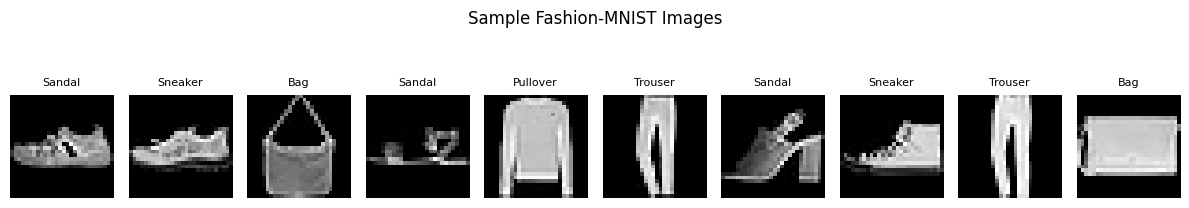

In [2]:
transform = transforms.ToTensor()
train_part = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_part = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)
full_dataset = ConcatDataset([train_part, test_part])

total_size = len(full_dataset)
train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size], generator=generator
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Total images: {total_size}")
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

sample_imgs, sample_labels = next(iter(train_loader))
plt.figure(figsize=(12, 2.5))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(sample_imgs[i].squeeze(), cmap="gray")
    plt.title(class_names[sample_labels[i].item()], fontsize=8)
    plt.axis("off")
plt.suptitle("Sample Fashion-MNIST Images")
plt.tight_layout()
plt.show()

## 2. MLP Classifier Experiment
Here we train a simple MLP Classifier on Fashion-MNIST, and then test three ways of trying to use it to reconstruct or generate images:
1. Weight Transpose Projection ($W^T$): Projecting latent features `z_MLP` back to pixel space using transposed weight matrices.
2. Separate Decoder on Frozen `z_MLP`: Freezing the classifier and training a decoder to reconstruct images from `z_MLP`.
3. **Prior Sampling ($z \sim \mathcal{N}(0, I)$): Feeding random Gaussian noise into that separate decoder.:

We also check whether $W^T W = I$ (orthogonality) holds for the trained weight matrices.


--- Training MLP Classifier ---
Epoch 1/10 | Train Loss: 0.6081
Epoch 2/10 | Train Loss: 0.4105
Epoch 3/10 | Train Loss: 0.3636
Epoch 4/10 | Train Loss: 0.3346
Epoch 5/10 | Train Loss: 0.3133
Epoch 6/10 | Train Loss: 0.2971
Epoch 7/10 | Train Loss: 0.2810
Epoch 8/10 | Train Loss: 0.2678
Epoch 9/10 | Train Loss: 0.2610
Epoch 10/10 | Train Loss: 0.2497
MLP Classifier Test Accuracy: 88.63%
Non-orthogonality ||W1^T W1 - I||_F = 276.14 (not 0 -> non-orthogonal)
Non-orthogonality ||W2^T W2 - I||_F = 39.39 (not 0 -> non-orthogonal)

--- Training Separate Decoder on Frozen z_MLP ---
Epoch 1/10 | Decoder MSE: 0.0357
Epoch 2/10 | Decoder MSE: 0.0241
Epoch 3/10 | Decoder MSE: 0.0219
Epoch 4/10 | Decoder MSE: 0.0207
Epoch 5/10 | Decoder MSE: 0.0200
Epoch 6/10 | Decoder MSE: 0.0195
Epoch 7/10 | Decoder MSE: 0.0190
Epoch 8/10 | Decoder MSE: 0.0187
Epoch 9/10 | Decoder MSE: 0.0184
Epoch 10/10 | Decoder MSE: 0.0182


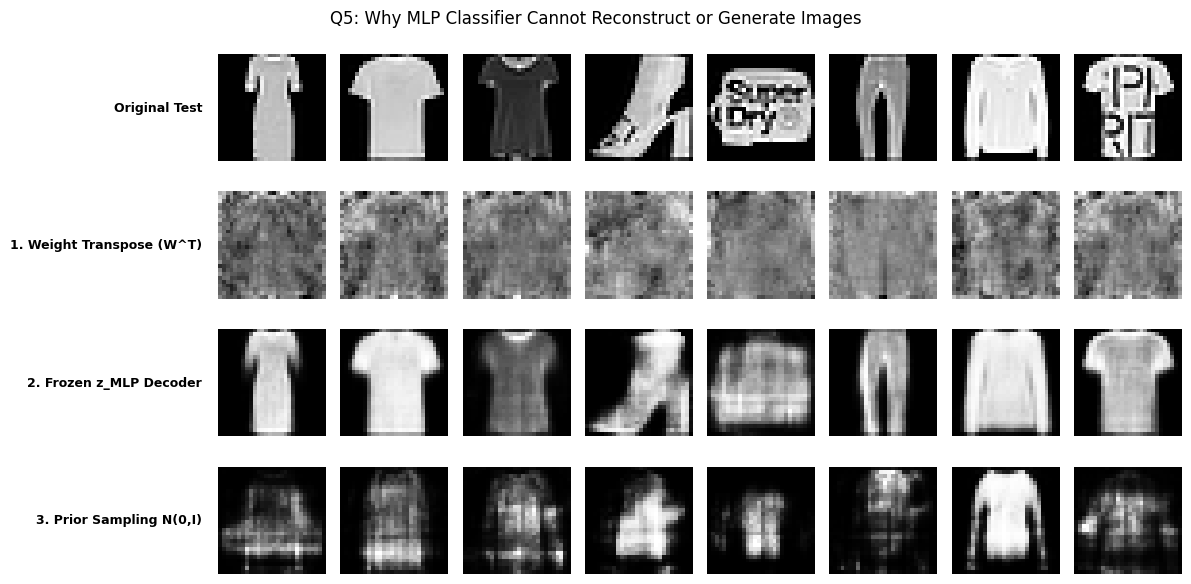

In [ ]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def get_latent(self, x):
        x = x.view(x.size(0), -1)
        h1 = F.relu(self.fc1(x))
        z = F.relu(self.fc2(h1))
        return z

    def forward(self, x):
        z = self.get_latent(x)
        logits = self.fc3(z)
        return logits

# Train the MLP Classifier
mlp_clf = MLPClassifier().to(device)
optimizer = torch.optim.Adam(mlp_clf.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

print("--- Training MLP Classifier ---")
for epoch in range(MLP_EPOCHS):
    mlp_clf.train()
    total_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = mlp_clf(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{MLP_EPOCHS} | Train Loss: {total_loss/len(train_loader):.4f}")

# Evaluate Test Accuracy
mlp_clf.eval()
correct = 0
total = 0
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        preds = mlp_clf(imgs).argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
print(f"MLP Classifier Test Accuracy: {100 * correct / total:.2f}%")

W1 = mlp_clf.fc1.weight.detach()
W2 = mlp_clf.fc2.weight.detach()
I1 = torch.eye(W1.shape[1], device=device)
I2 = torch.eye(W2.shape[1], device=device)
ortho_err_1 = torch.norm(W1.T @ W1 - I1).item()
ortho_err_2 = torch.norm(W2.T @ W2 - I2).item()
print(f"Non-orthogonality ||W1^T W1 - I||_F = {ortho_err_1:.2f} (not 0 -> non-orthogonal)")
print(f"Non-orthogonality ||W2^T W2 - I||_F = {ortho_err_2:.2f} (not 0 -> non-orthogonal)")

for param in mlp_clf.parameters():
    param.requires_grad = False

class FrozenFeatureDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

mlp_decoder = FrozenFeatureDecoder().to(device)
dec_opt = torch.optim.Adam(mlp_decoder.parameters(), lr=1e-3)
mse_loss = nn.MSELoss()

print("\n--- Training Separate Decoder on Frozen z_MLP ---")
for epoch in range(MLP_EPOCHS):
    mlp_decoder.train()
    total_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        with torch.no_grad():
            z_mlp = mlp_clf.get_latent(imgs)
        recon = mlp_decoder(z_mlp)
        loss = mse_loss(recon, imgs)
        dec_opt.zero_grad()
        loss.backward()
        dec_opt.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{MLP_EPOCHS} | Decoder MSE: {total_loss/len(train_loader):.4f}")

test_imgs, _ = next(iter(test_loader))
test_imgs_8 = test_imgs[:8].to(device)

mlp_clf.eval()
mlp_decoder.eval()
with torch.no_grad():
    z_mlp = mlp_clf.get_latent(test_imgs_8)

    proj = (z_mlp @ W2) @ W1
    proj_imgs = proj.view(-1, 1, 28, 28)
    proj_min = proj_imgs.amin(dim=(2, 3), keepdim=True)
    proj_max = proj_imgs.amax(dim=(2, 3), keepdim=True)
    proj_imgs = (proj_imgs - proj_min) / (proj_max - proj_min + 1e-8)

    frozen_recon = mlp_decoder(z_mlp)

    z_random = torch.randn(8, 64, device=device)
    prior_samples = mlp_decoder(z_random)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
row_titles = [
    "Original Test",
    "1. Weight Transpose (W^T)",
    "2. Frozen z_MLP Decoder",
    "3. Prior Sampling N(0,I)"
]
rows_data = [test_imgs_8, proj_imgs, frozen_recon, prior_samples]

for r in range(4):
    for c in range(8):
        axes[r, c].imshow(rows_data[r][c].cpu().squeeze(), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].text(-0.15, 0.5, row_titles[r], transform=axes[r, 0].transAxes, fontsize=9, fontweight="bold", ha="right", va="center")

plt.suptitle("Q5: Why MLP Classifier Cannot Reconstruct or Generate Images", fontsize=12)
plt.tight_layout()
plt.show()

## 3. Model 1: Vanilla Autoencoder (Vanilla AE)

In [6]:
class VanillaAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x.view(x.size(0), -1))

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        recon = self.decode(z)
        return recon, z

vanilla_ae = VanillaAE().to(device)
optimizer = torch.optim.Adam(vanilla_ae.parameters(), lr=1e-3)
criterion = nn.MSELoss()

print("--- Training Vanilla Autoencoder ---")
for epoch in range(AE_EPOCHS):
    vanilla_ae.train()
    train_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        recon, _ = vanilla_ae(imgs)
        loss = criterion(recon, imgs)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    vanilla_ae.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, _ in val_loader:
            imgs = imgs.to(device)
            recon, _ = vanilla_ae(imgs)
            val_loss += criterion(recon, imgs).item()

    print(f"Epoch {epoch+1:2d}/{AE_EPOCHS} | Train MSE: {train_loss/len(train_loader):.5f} | Val MSE: {val_loss/len(val_loader):.5f}")

--- Training Vanilla Autoencoder ---
Epoch  1/15 | Train MSE: 0.04093 | Val MSE: 0.02379
Epoch  2/15 | Train MSE: 0.02179 | Val MSE: 0.02054
Epoch  3/15 | Train MSE: 0.01894 | Val MSE: 0.01816
Epoch  4/15 | Train MSE: 0.01734 | Val MSE: 0.01705
Epoch  5/15 | Train MSE: 0.01637 | Val MSE: 0.01616
Epoch  6/15 | Train MSE: 0.01551 | Val MSE: 0.01546
Epoch  7/15 | Train MSE: 0.01485 | Val MSE: 0.01486
Epoch  8/15 | Train MSE: 0.01432 | Val MSE: 0.01440
Epoch  9/15 | Train MSE: 0.01386 | Val MSE: 0.01386
Epoch 10/15 | Train MSE: 0.01346 | Val MSE: 0.01366
Epoch 11/15 | Train MSE: 0.01315 | Val MSE: 0.01333
Epoch 12/15 | Train MSE: 0.01287 | Val MSE: 0.01308
Epoch 13/15 | Train MSE: 0.01265 | Val MSE: 0.01280
Epoch 14/15 | Train MSE: 0.01243 | Val MSE: 0.01273
Epoch 15/15 | Train MSE: 0.01225 | Val MSE: 0.01251


## 4. Model 2: Sparse Autoencoder (Sparse AE)

In [8]:
sparse_ae = VanillaAE().to(device)
optimizer = torch.optim.Adam(sparse_ae.parameters(), lr=1e-3)
criterion = nn.MSELoss()

print(f"--- Training Sparse Autoencoder (lambda_L1 = {LAMBDA_L1}) ---")
for epoch in range(AE_EPOCHS):
    sparse_ae.train()
    train_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        recon, h = sparse_ae(imgs)
        mse = criterion(recon, imgs)
        l1_penalty = torch.mean(torch.abs(h))
        loss = mse + LAMBDA_L1 * l1_penalty

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += mse.item()

    sparse_ae.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, _ in val_loader:
            imgs = imgs.to(device)
            recon, _ = sparse_ae(imgs)
            val_loss += criterion(recon, imgs).item()

    print(f"Epoch {epoch+1:2d}/{AE_EPOCHS} | Train MSE: {train_loss/len(train_loader):.5f} | Val MSE: {val_loss/len(val_loader):.5f}")

--- Training Sparse Autoencoder (lambda_L1 = 0.001) ---
Epoch  1/15 | Train MSE: 0.04249 | Val MSE: 0.02364
Epoch  2/15 | Train MSE: 0.02110 | Val MSE: 0.01962
Epoch  3/15 | Train MSE: 0.01849 | Val MSE: 0.01812
Epoch  4/15 | Train MSE: 0.01722 | Val MSE: 0.01694
Epoch  5/15 | Train MSE: 0.01619 | Val MSE: 0.01604
Epoch  6/15 | Train MSE: 0.01540 | Val MSE: 0.01538
Epoch  7/15 | Train MSE: 0.01477 | Val MSE: 0.01492
Epoch  8/15 | Train MSE: 0.01430 | Val MSE: 0.01439
Epoch  9/15 | Train MSE: 0.01379 | Val MSE: 0.01390
Epoch 10/15 | Train MSE: 0.01343 | Val MSE: 0.01354
Epoch 11/15 | Train MSE: 0.01313 | Val MSE: 0.01327
Epoch 12/15 | Train MSE: 0.01288 | Val MSE: 0.01305
Epoch 13/15 | Train MSE: 0.01265 | Val MSE: 0.01295
Epoch 14/15 | Train MSE: 0.01245 | Val MSE: 0.01270
Epoch 15/15 | Train MSE: 0.01228 | Val MSE: 0.01275


## 5. Model 3: Variational Autoencoder (VAE)


In [10]:
class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = F.relu(self.fc1(x.view(x.size(0), -1)))
        h = F.relu(self.fc2(h))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar

def vae_loss_fn(recon, x, mu, logvar):
    bce = F.binary_cross_entropy(recon, x, reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return (bce + kl) / x.size(0)

vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

print("--- Training Variational Autoencoder (VAE) ---")
for epoch in range(AE_EPOCHS):
    vae.train()
    train_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        recon, mu, logvar = vae(imgs)
        loss = vae_loss_fn(recon, imgs, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    vae.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, _ in val_loader:
            imgs = imgs.to(device)
            recon, mu, logvar = vae(imgs)
            val_loss += vae_loss_fn(recon, imgs, mu, logvar).item()

    print(f"Epoch {epoch+1:2d}/{AE_EPOCHS} | Train Loss: {train_loss/len(train_loader):.2f} | Val Loss: {val_loss/len(val_loader):.2f}")

--- Training Variational Autoencoder (VAE) ---
Epoch  1/15 | Train Loss: 307.62 | Val Loss: 276.00
Epoch  2/15 | Train Loss: 266.27 | Val Loss: 261.50
Epoch  3/15 | Train Loss: 256.60 | Val Loss: 254.25
Epoch  4/15 | Train Loss: 251.35 | Val Loss: 250.46
Epoch  5/15 | Train Loss: 248.42 | Val Loss: 248.26
Epoch  6/15 | Train Loss: 246.45 | Val Loss: 246.49
Epoch  7/15 | Train Loss: 245.17 | Val Loss: 245.42
Epoch  8/15 | Train Loss: 244.21 | Val Loss: 244.60
Epoch  9/15 | Train Loss: 243.46 | Val Loss: 244.37
Epoch 10/15 | Train Loss: 242.92 | Val Loss: 243.66
Epoch 11/15 | Train Loss: 242.43 | Val Loss: 243.31
Epoch 12/15 | Train Loss: 242.05 | Val Loss: 243.02
Epoch 13/15 | Train Loss: 241.72 | Val Loss: 242.83
Epoch 14/15 | Train Loss: 241.35 | Val Loss: 242.30
Epoch 15/15 | Train Loss: 241.07 | Val Loss: 242.10


## 6. Model 4: Vanilla GAN (MLP-based)

In [12]:
class VanillaGenerator(nn.Module):
    def __init__(self, latent_dim=GAN_LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 28 * 28),
            nn.Tanh()
        )
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class VanillaDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x.view(x.size(0), -1))

vgan_G = VanillaGenerator().to(device)
vgan_D = VanillaDiscriminator().to(device)

opt_G = torch.optim.Adam(vgan_G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(vgan_D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCELoss()

vgan_g_losses = []
vgan_d_losses = []

print("--- Training Vanilla GAN (MLP) ---")
for epoch in range(GAN_EPOCHS):
    vgan_G.train()
    vgan_D.train()
    g_epoch_loss = 0.0
    d_epoch_loss = 0.0

    for imgs, _ in train_loader:
        batch_size = imgs.size(0)
        real_imgs = imgs.to(device) * 2.0 - 1.0  # Scale [0, 1] -> [-1, 1]

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # 1. Train Discriminator
        z = torch.randn(batch_size, GAN_LATENT_DIM, device=device)
        fake_imgs = vgan_G(z)

        loss_D_real = bce(vgan_D(real_imgs), real_labels)
        loss_D_fake = bce(vgan_D(fake_imgs.detach()), fake_labels)
        loss_D = (loss_D_real + loss_D_fake) / 2

        opt_D.zero_grad()
        loss_D.backward()
        opt_D.step()

        # 2. Train Generator
        loss_G = bce(vgan_D(fake_imgs), real_labels)
        opt_G.zero_grad()
        loss_G.backward()
        opt_G.step()

        d_epoch_loss += loss_D.item()
        g_epoch_loss += loss_G.item()

    vgan_d_losses.append(d_epoch_loss / len(train_loader))
    vgan_g_losses.append(g_epoch_loss / len(train_loader))
    print(f"Epoch {epoch+1:2d}/{GAN_EPOCHS} | D Loss: {vgan_d_losses[-1]:.4f} | G Loss: {vgan_g_losses[-1]:.4f}")

--- Training Vanilla GAN (MLP) ---
Epoch  1/20 | D Loss: 0.3534 | G Loss: 1.8121
Epoch  2/20 | D Loss: 0.3083 | G Loss: 2.7632
Epoch  3/20 | D Loss: 0.3693 | G Loss: 2.3341
Epoch  4/20 | D Loss: 0.4031 | G Loss: 2.1011
Epoch  5/20 | D Loss: 0.4209 | G Loss: 1.9978
Epoch  6/20 | D Loss: 0.4395 | G Loss: 1.9146
Epoch  7/20 | D Loss: 0.4402 | G Loss: 1.8945
Epoch  8/20 | D Loss: 0.4362 | G Loss: 1.8805
Epoch  9/20 | D Loss: 0.4651 | G Loss: 1.7830
Epoch 10/20 | D Loss: 0.4789 | G Loss: 1.7052
Epoch 11/20 | D Loss: 0.4707 | G Loss: 1.7282
Epoch 12/20 | D Loss: 0.4783 | G Loss: 1.6894
Epoch 13/20 | D Loss: 0.4786 | G Loss: 1.6724
Epoch 14/20 | D Loss: 0.4960 | G Loss: 1.6018
Epoch 15/20 | D Loss: 0.4970 | G Loss: 1.5865
Epoch 16/20 | D Loss: 0.4997 | G Loss: 1.5345
Epoch 17/20 | D Loss: 0.4991 | G Loss: 1.4970
Epoch 18/20 | D Loss: 0.5070 | G Loss: 1.5052
Epoch 19/20 | D Loss: 0.5048 | G Loss: 1.5116
Epoch 20/20 | D Loss: 0.5007 | G Loss: 1.4972


## 7. Model 5: DCGAN (Deep Convolutional GAN)


In [3]:
def init_dcgan_weights(m):
    classname = m.__class__.__name__
    if "Conv" in classname:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif "BatchNorm" in classname:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

class DCGANGenerator(nn.Module):
    def __init__(self, latent_dim=GAN_LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 256, kernel_size=7, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 1, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        )
    def forward(self, z):
        return self.net(z.view(z.size(0), z.size(1), 1, 1))

class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 1, kernel_size=7, stride=1, padding=0, bias=False),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x).view(-1, 1)

dcgan_G = DCGANGenerator().to(device)
dcgan_D = DCGANDiscriminator().to(device)
dcgan_G.apply(init_dcgan_weights)
dcgan_D.apply(init_dcgan_weights)

opt_G = torch.optim.Adam(dcgan_G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(dcgan_D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCELoss()

dcgan_g_losses = []
dcgan_d_losses = []

print("--- Training DCGAN ---")
for epoch in range(GAN_EPOCHS):
    dcgan_G.train()
    dcgan_D.train()
    g_epoch_loss = 0.0
    d_epoch_loss = 0.0

    for imgs, _ in train_loader:
        batch_size = imgs.size(0)
        real_imgs = imgs.to(device) * 2.0 - 1.0  # Scale [0, 1] -> [-1, 1]

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        z = torch.randn(batch_size, GAN_LATENT_DIM, device=device)
        fake_imgs = dcgan_G(z)

        loss_D_real = bce(dcgan_D(real_imgs), real_labels)
        loss_D_fake = bce(dcgan_D(fake_imgs.detach()), fake_labels)
        loss_D = (loss_D_real + loss_D_fake) / 2

        opt_D.zero_grad()
        loss_D.backward()
        opt_D.step()

        loss_G = bce(dcgan_D(fake_imgs), real_labels)
        opt_G.zero_grad()
        loss_G.backward()
        opt_G.step()

        d_epoch_loss += loss_D.item()
        g_epoch_loss += loss_G.item()

    dcgan_d_losses.append(d_epoch_loss / len(train_loader))
    dcgan_g_losses.append(g_epoch_loss / len(train_loader))
    print(f"Epoch {epoch+1:2d}/{GAN_EPOCHS} | D Loss: {dcgan_d_losses[-1]:.4f} | G Loss: {dcgan_g_losses[-1]:.4f}")

--- Training DCGAN ---
Epoch  1/20 | D Loss: 0.3640 | G Loss: 1.5776
Epoch  2/20 | D Loss: 0.3819 | G Loss: 1.5277
Epoch  3/20 | D Loss: 0.4802 | G Loss: 1.2772
Epoch  4/20 | D Loss: 0.5315 | G Loss: 1.1679
Epoch  5/20 | D Loss: 0.5451 | G Loss: 1.1342
Epoch  6/20 | D Loss: 0.5538 | G Loss: 1.1397
Epoch  7/20 | D Loss: 0.5567 | G Loss: 1.1195
Epoch  8/20 | D Loss: 0.5693 | G Loss: 1.1081
Epoch  9/20 | D Loss: 0.5759 | G Loss: 1.0945
Epoch 10/20 | D Loss: 0.5828 | G Loss: 1.0780
Epoch 11/20 | D Loss: 0.5918 | G Loss: 1.0719
Epoch 12/20 | D Loss: 0.5933 | G Loss: 1.0557
Epoch 13/20 | D Loss: 0.5964 | G Loss: 1.0525
Epoch 14/20 | D Loss: 0.6010 | G Loss: 1.0494
Epoch 15/20 | D Loss: 0.6027 | G Loss: 1.0437
Epoch 16/20 | D Loss: 0.6061 | G Loss: 1.0403
Epoch 17/20 | D Loss: 0.6057 | G Loss: 1.0333
Epoch 18/20 | D Loss: 0.6110 | G Loss: 1.0329
Epoch 19/20 | D Loss: 0.6147 | G Loss: 1.0327
Epoch 20/20 | D Loss: 0.6117 | G Loss: 1.0170


## 8. Model 6: DDPM (Simple Denoising Diffusion Probabilistic Model)



In [4]:
betas = torch.linspace(1e-4, 0.02, TIMESTEPS, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

def add_noise(x0, t):
    """Forward diffusion process: adds noise to x0 at timestep t."""
    noise = torch.randn_like(x0)
    sqrt_ab = torch.sqrt(alpha_bars[t]).view(-1, 1, 1, 1)
    sqrt_one_minus_ab = torch.sqrt(1.0 - alpha_bars[t]).view(-1, 1, 1, 1)
    noisy_x = sqrt_ab * x0 + sqrt_one_minus_ab * noise
    return noisy_x, noise

class SimpleUNet(nn.Module):
    def __init__(self, timesteps=TIMESTEPS):
        super().__init__()
        self.time_emb1 = nn.Embedding(timesteps, 32)
        self.time_emb2 = nn.Embedding(timesteps, 64)

        self.down1 = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        self.pool1 = nn.MaxPool2d(2)

        self.down2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.pool2 = nn.MaxPool2d(2)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )

        self.up2 = nn.ConvTranspose2d(64, 64, 2, stride=2)
        self.dec2 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )
        self.out = nn.Conv2d(32, 1, 1)

    def forward(self, x, t):
        t1 = self.time_emb1(t).view(-1, 32, 1, 1)
        t2 = self.time_emb2(t).view(-1, 64, 1, 1)

        d1 = self.down1(x) + t1
        d2 = self.down2(self.pool1(d1)) + t2
        b = self.bottleneck(self.pool2(d2)) + t2

        u2 = self.dec2(torch.cat([self.up2(b), d2], dim=1))
        u1 = self.dec1(torch.cat([self.up1(u2), d1], dim=1))
        return self.out(u1)

ddpm_model = SimpleUNet().to(device)
optimizer = torch.optim.Adam(ddpm_model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

ddpm_losses = []

print("--- Training DDPM ---")
for epoch in range(DDPM_EPOCHS):
    ddpm_model.train()
    epoch_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device) * 2.0 - 1.0  # Scale [0, 1] -> [-1, 1]
        t = torch.randint(0, TIMESTEPS, (imgs.size(0),), device=device)

        noisy_imgs, true_noise = add_noise(imgs, t)
        pred_noise = ddpm_model(noisy_imgs, t)
        loss = criterion(pred_noise, true_noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    ddpm_losses.append(epoch_loss / len(train_loader))
    print(f"Epoch {epoch+1:2d}/{DDPM_EPOCHS} | Noise Prediction MSE: {ddpm_losses[-1]:.5f}")

@torch.no_grad()
def sample_ddpm(num_samples):
    """Reverse diffusion process: iteratively denoise from random noise."""
    ddpm_model.eval()
    x = torch.randn(num_samples, 1, 28, 28, device=device)
    for step in reversed(range(TIMESTEPS)):
        t = torch.full((num_samples,), step, device=device, dtype=torch.long)
        pred_noise = ddpm_model(x, t)

        alpha = alphas[step]
        alpha_bar = alpha_bars[step]
        beta = betas[step]

        mean = (1.0 / torch.sqrt(alpha)) * (x - ((1.0 - alpha) / torch.sqrt(1.0 - alpha_bar)) * pred_noise)
        if step > 0:
            x = mean + torch.sqrt(beta) * torch.randn_like(x)
        else:
            x = mean

    return ((x + 1.0) / 2.0).clamp(0.0, 1.0)

--- Training DDPM ---
Epoch  1/20 | Noise Prediction MSE: 0.19459
Epoch  2/20 | Noise Prediction MSE: 0.13578
Epoch  3/20 | Noise Prediction MSE: 0.12509
Epoch  4/20 | Noise Prediction MSE: 0.11838
Epoch  5/20 | Noise Prediction MSE: 0.11398
Epoch  6/20 | Noise Prediction MSE: 0.11201
Epoch  7/20 | Noise Prediction MSE: 0.10935
Epoch  8/20 | Noise Prediction MSE: 0.10753
Epoch  9/20 | Noise Prediction MSE: 0.10637
Epoch 10/20 | Noise Prediction MSE: 0.10475
Epoch 11/20 | Noise Prediction MSE: 0.10485
Epoch 12/20 | Noise Prediction MSE: 0.10383
Epoch 13/20 | Noise Prediction MSE: 0.10297
Epoch 14/20 | Noise Prediction MSE: 0.10132
Epoch 15/20 | Noise Prediction MSE: 0.10223
Epoch 16/20 | Noise Prediction MSE: 0.10046
Epoch 17/20 | Noise Prediction MSE: 0.10059
Epoch 18/20 | Noise Prediction MSE: 0.09960
Epoch 19/20 | Noise Prediction MSE: 0.09884
Epoch 20/20 | Noise Prediction MSE: 0.09908


## 9. Q1 Evaluation: Reconstruction Fidelity (MSE, PSNR, SSIM) & Generative Quality (FID)
All metrics are evaluated on the unseen Test Set:
- Vanilla AE, Sparse AE, VAE: Test MSE, Test PSNR, and Test SSIM.
- VAE, Vanilla GAN, DCGAN, DDPM: Fréchet Inception Distance (FID) using pretrained `InceptionV3` features on 1,000 real test images vs 1,000 generated images.


In [14]:
@torch.no_grad()
def evaluate_reconstruction(model, loader, is_vae=False):
    model.eval()
    mse_list = []
    psnr_list = []
    ssim_list = []

    for imgs, _ in loader:
        imgs = imgs.to(device)
        if is_vae:
            recon, _, _ = model(imgs)
        else:
            recon, _ = model(imgs)

        imgs_np = imgs.cpu().numpy()
        recon_np = recon.cpu().numpy()

        for i in range(imgs_np.shape[0]):
            orig = imgs_np[i, 0]
            rec = recon_np[i, 0]
            mse_val = np.mean((orig - rec) ** 2)
            psnr_val = 10.0 * np.log10(1.0 / (mse_val + 1e-10))
            ssim_val = ssim(orig, rec, data_range=1.0)

            mse_list.append(mse_val)
            psnr_list.append(psnr_val)
            ssim_list.append(ssim_val)

    return np.mean(mse_list), np.mean(psnr_list), np.mean(ssim_list)

recon_results = {}
for name, model, is_vae in [
    ("Vanilla AE", vanilla_ae, False),
    ("Sparse AE", sparse_ae, False),
    ("VAE", vae, True)
]:
    m_mse, m_psnr, m_ssim = evaluate_reconstruction(model, test_loader, is_vae=is_vae)
    recon_results[name] = {"Test MSE": m_mse, "Test PSNR (dB)": m_psnr, "Test SSIM": m_ssim}

recon_df = pd.DataFrame(recon_results).T
print("=== Q1: Reconstruction Metrics on Test Set ===")
display(recon_df)

inception = models.inception_v3(weights=models.Inception_V3_Weights.DEFAULT, transform_input=False)
inception.fc = nn.Identity()
inception = inception.to(device)
inception.eval()

@torch.no_grad()
def get_inception_features(images_tensor, batch_size=64):
    """Extract 2048-dim InceptionV3 features from [N, 1, 28, 28] images in [0, 1]."""
    feats = []
    for i in range(0, len(images_tensor), batch_size):
        batch = images_tensor[i:i+batch_size].to(device)
        batch = batch.repeat(1, 3, 1, 1)
        batch = F.interpolate(batch, size=(299, 299), mode="bilinear", align_corners=False)
        mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
        batch = (batch - mean) / std
        f = inception(batch)
        feats.append(f.cpu().numpy())
    return np.concatenate(feats, axis=0)

def compute_fid(real_imgs, fake_imgs):
    real_feats = get_inception_features(real_imgs)
    fake_feats = get_inception_features(fake_imgs)

    mu1, sigma1 = np.mean(real_feats, axis=0), np.cov(real_feats, rowvar=False)
    mu2, sigma2 = np.mean(fake_feats, axis=0), np.cov(fake_feats, rowvar=False)

    diff = mu1 - mu2
    covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = diff.dot(diff) + np.trace(sigma1 + sigma2 - 2.0 * covmean)
    return float(fid)

N_FID = 1000
real_list = []
for imgs, _ in test_loader:
    real_list.append(imgs)
    if sum(len(x) for x in real_list) >= N_FID:
        break
real_fid_imgs = torch.cat(real_list, dim=0)[:N_FID]

@torch.no_grad()
def generate_samples(model_name, num_samples):
    imgs_out = []
    batch_sz = 100
    for start in range(0, num_samples, batch_sz):
        curr = min(batch_sz, num_samples - start)
        if model_name == "VAE":
            vae.eval()
            z = torch.randn(curr, LATENT_DIM, device=device)
            out = vae.decode(z)
        elif model_name == "Vanilla GAN":
            vgan_G.eval()
            z = torch.randn(curr, GAN_LATENT_DIM, device=device)
            out = ((vgan_G(z) + 1.0) / 2.0).clamp(0.0, 1.0)
        elif model_name == "DCGAN":
            dcgan_G.eval()
            z = torch.randn(curr, GAN_LATENT_DIM, device=device)
            out = ((dcgan_G(z) + 1.0) / 2.0).clamp(0.0, 1.0)
        elif model_name == "DDPM":
            out = sample_ddpm(curr)
        imgs_out.append(out.cpu())
    return torch.cat(imgs_out, dim=0)

print("\nCalculating FID scores (lower is better)...")
fid_results = {}
generated_preview = {}
for name in ["VAE", "Vanilla GAN", "DCGAN", "DDPM"]:
    fake_imgs = generate_samples(name, N_FID)
    generated_preview[name] = fake_imgs[:16]  # Save 16 images to plot in Q2
    fid_score = compute_fid(real_fid_imgs, fake_imgs)
    fid_results[name] = fid_score
    print(f"{name:12s} | FID: {fid_score:.2f}")

=== Q1: Reconstruction Metrics on Test Set ===


,Test MSE,Test PSNR (dB),Test SSIM
Vanilla AE,0.012424,19.948984,0.712932
Sparse AE,0.012679,19.827066,0.713986
VAE,0.017066,18.384121,0.664241



Calculating FID scores (lower is better)...


/tmp/ipykernel_363/1080521332.py:72: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


VAE          | FID: 106.14
Vanilla GAN  | FID: 210.27
DCGAN        | FID: 46.19
DDPM         | FID: 132.94


## 10. Q2 Analysis: Blurriness vs Sharp Edges & Feature Representation
1. Visual comparison of Reconstructions (Vanilla AE, Sparse AE, VAE) vs Generated Samples (VAE, Vanilla GAN, DCGAN, DDPM).
2. Feature representation comparison between Vanilla AE and Sparse AE (latent activation histogram, sparsity ratio, and first-layer encoder weights).


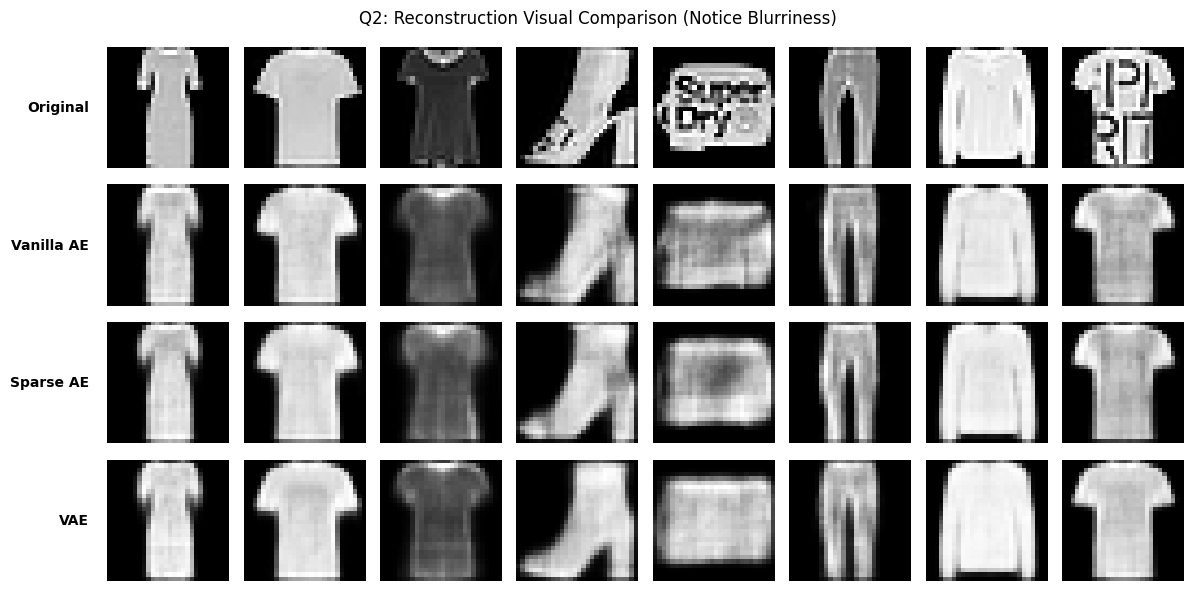

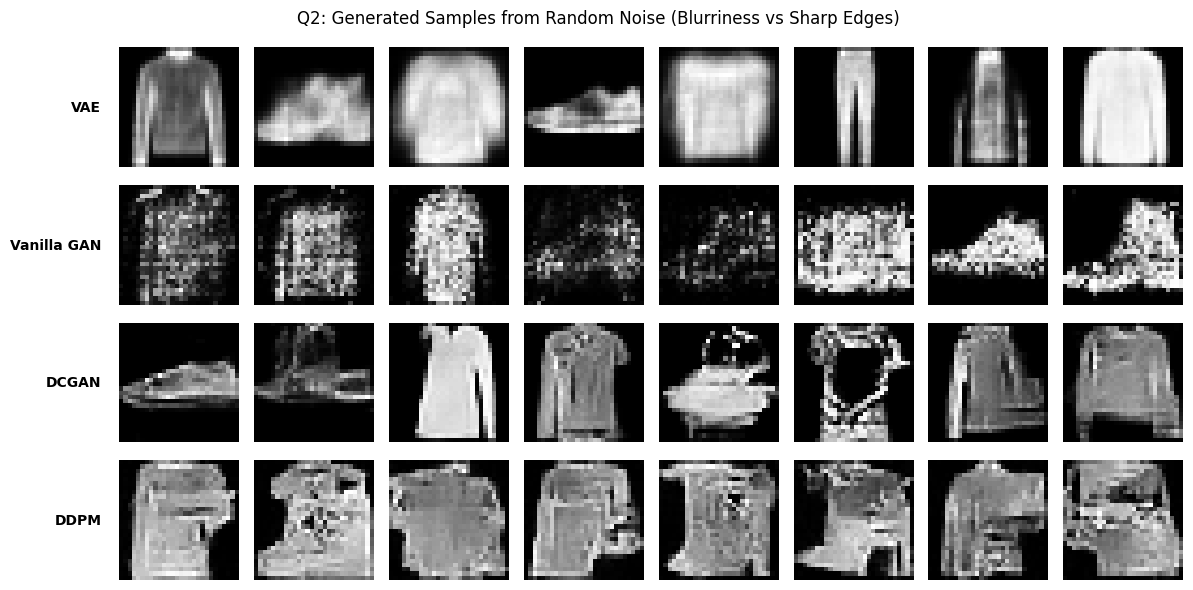

Vanilla AE near-zero latent activations (|h| < 0.05): 27.91%
Sparse AE  near-zero latent activations (|h| < 0.05): 42.70%


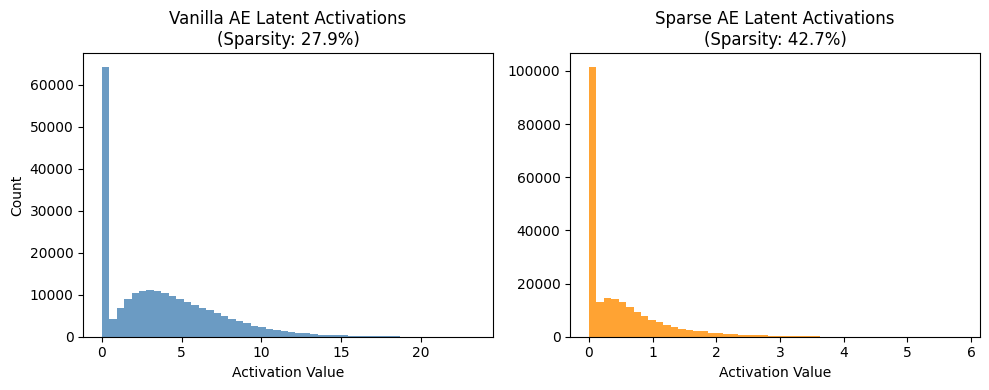

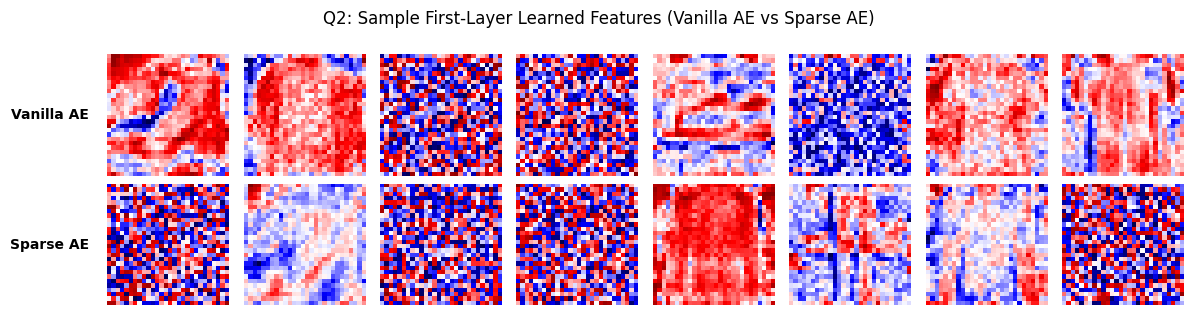

In [15]:
test_imgs, _ = next(iter(test_loader))
test_8 = test_imgs[:8].to(device)

with torch.no_grad():
    rec_vae, _, _ = vae(test_8)
    rec_van, _ = vanilla_ae(test_8)
    rec_spa, _ = sparse_ae(test_8)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
names = ["Original", "Vanilla AE", "Sparse AE", "VAE"]
imgs_rows = [test_8, rec_van, rec_spa, rec_vae]

for r in range(4):
    for c in range(8):
        axes[r, c].imshow(imgs_rows[r][c].cpu().squeeze(), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].text(-0.15, 0.5, names[r], transform=axes[r, 0].transAxes, fontsize=10, fontweight="bold", ha="right", va="center")
plt.suptitle("Q2: Reconstruction Visual Comparison (Notice Blurriness)", fontsize=12)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
gen_names = ["VAE", "Vanilla GAN", "DCGAN", "DDPM"]
for r, name in enumerate(gen_names):
    for c in range(8):
        axes[r, c].imshow(generated_preview[name][c].squeeze(), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].text(-0.15, 0.5, name, transform=axes[r, 0].transAxes, fontsize=10, fontweight="bold", ha="right", va="center")
plt.suptitle("Q2: Generated Samples from Random Noise (Blurriness vs Sharp Edges)", fontsize=12)
plt.tight_layout()
plt.show()

vanilla_ae.eval()
sparse_ae.eval()
van_acts, spa_acts = [], []

with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        _, z_v = vanilla_ae(imgs)
        _, z_s = sparse_ae(imgs)
        van_acts.append(z_v.cpu().numpy())
        spa_acts.append(z_s.cpu().numpy())

van_acts = np.concatenate(van_acts, axis=0).flatten()
spa_acts = np.concatenate(spa_acts, axis=0).flatten()

van_sparsity = 100.0 * np.mean(np.abs(van_acts) < 0.05)
spa_sparsity = 100.0 * np.mean(np.abs(spa_acts) < 0.05)
print(f"Vanilla AE near-zero latent activations (|h| < 0.05): {van_sparsity:.2f}%")
print(f"Sparse AE  near-zero latent activations (|h| < 0.05): {spa_sparsity:.2f}%")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(van_acts, bins=50, color="steelblue", alpha=0.8)
plt.title(f"Vanilla AE Latent Activations\n(Sparsity: {van_sparsity:.1f}%)")
plt.xlabel("Activation Value")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
plt.hist(spa_acts, bins=50, color="darkorange", alpha=0.8)
plt.title(f"Sparse AE Latent Activations\n(Sparsity: {spa_sparsity:.1f}%)")
plt.xlabel("Activation Value")
plt.tight_layout()
plt.show()

w_van = vanilla_ae.encoder[0].weight.detach().cpu().view(-1, 28, 28)
w_spa = sparse_ae.encoder[0].weight.detach().cpu().view(-1, 28, 28)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i in range(8):
    axes[0, i].imshow(w_van[i], cmap="seismic")
    axes[0, i].axis("off")
    axes[1, i].imshow(w_spa[i], cmap="seismic")
    axes[1, i].axis("off")
axes[0, 0].text(-0.15, 0.5, "Vanilla AE", transform=axes[0, 0].transAxes, fontsize=10, fontweight="bold", ha="right", va="center")
axes[1, 0].text(-0.15, 0.5, "Sparse AE", transform=axes[1, 0].transAxes, fontsize=10, fontweight="bold", ha="right", va="center")
plt.suptitle("Q2: Sample First-Layer Learned Features (Vanilla AE vs Sparse AE)")
plt.tight_layout()
plt.show()

## 11. Q3 Analysis: Training Stability & Generative Trilemma (Inference Latency)
1. Plot training loss curves for Vanilla GAN, DCGAN, and DDPM.
2. Measure inference latency (ms) to generate a single batch of 64 images for VAE, Vanilla GAN, DCGAN (single-pass) vs DDPM (multi-step iterative denoising).


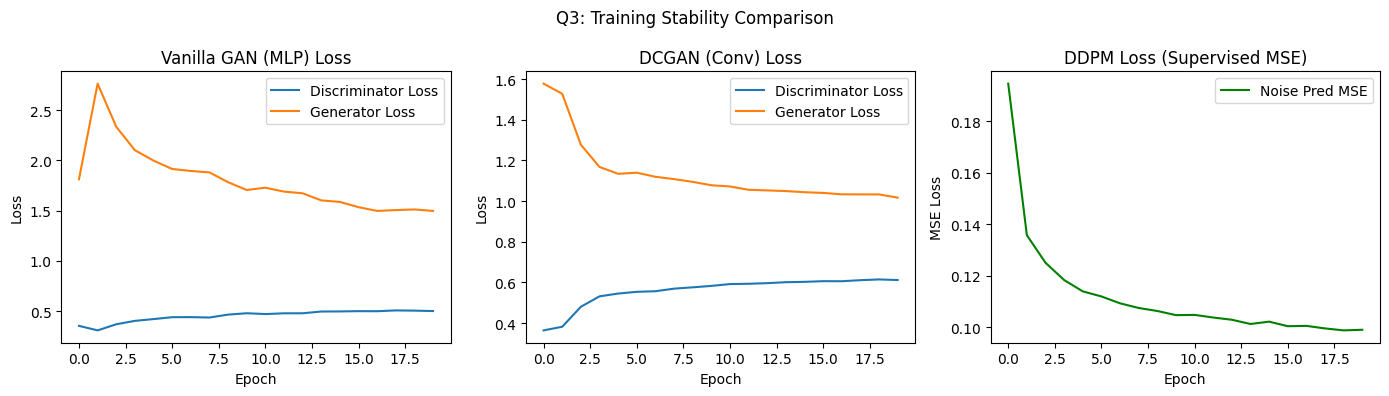

=== Q3: Inference Latency per Batch (64 Images) ===
VAE          | 0.41 ms
Vanilla GAN  | 0.31 ms
DCGAN        | 4.95 ms
DDPM         | 585.84 ms


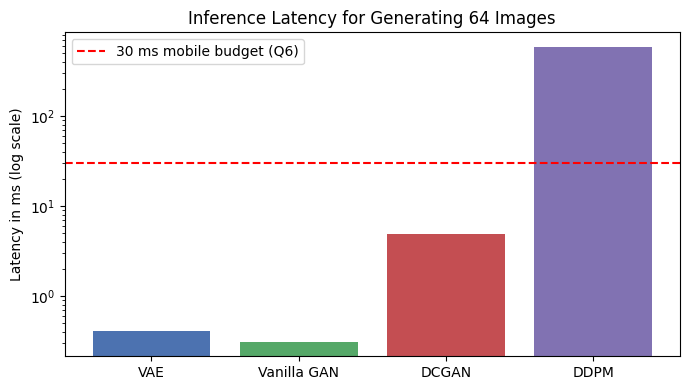

In [16]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.plot(vgan_d_losses, label="Discriminator Loss")
plt.plot(vgan_g_losses, label="Generator Loss")
plt.title("Vanilla GAN (MLP) Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(dcgan_d_losses, label="Discriminator Loss")
plt.plot(dcgan_g_losses, label="Generator Loss")
plt.title("DCGAN (Conv) Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(ddpm_losses, color="green", label="Noise Pred MSE")
plt.title("DDPM Loss (Supervised MSE)")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()

plt.suptitle("Q3: Training Stability Comparison")
plt.tight_layout()
plt.show()

@torch.no_grad()
def measure_latency_ms(fn, runs=5):
    fn()
    if device.type == "cuda":
        torch.cuda.synchronize()

    times = []
    for _ in range(runs):
        start = time.time()
        fn()
        if device.type == "cuda":
            torch.cuda.synchronize()
        times.append((time.time() - start) * 1000.0)
    return np.mean(times)

vae.eval()
vgan_G.eval()
dcgan_G.eval()
ddpm_model.eval()

latencies = {
    "VAE": measure_latency_ms(lambda: vae.decode(torch.randn(64, LATENT_DIM, device=device))),
    "Vanilla GAN": measure_latency_ms(lambda: vgan_G(torch.randn(64, GAN_LATENT_DIM, device=device))),
    "DCGAN": measure_latency_ms(lambda: dcgan_G(torch.randn(64, GAN_LATENT_DIM, device=device))),
    "DDPM": measure_latency_ms(lambda: sample_ddpm(64), runs=3)
}

print("=== Q3: Inference Latency per Batch (64 Images) ===")
for name, ms in latencies.items():
    print(f"{name:12s} | {ms:.2f} ms")

plt.figure(figsize=(7, 4))
plt.bar(latencies.keys(), latencies.values(), color=["#4c72b0", "#55a868", "#c44e52", "#8172b2"])
plt.axhline(30, color="red", linestyle="--", label="30 ms mobile budget (Q6)")
plt.yscale("log")
plt.ylabel("Latency in ms (log scale)")
plt.xticks(rotation=0)
plt.title("Inference Latency for Generating 64 Images")
plt.legend()
plt.tight_layout()
plt.show()

## 12. Q4 Analysis: Latent Space Linear Interpolation
Linearly interpolate between two latent vectors $z_A$ and $z_B$:
$$z(\alpha) = (1 - \alpha) z_A + \alpha z_B, \quad \alpha \in [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]$$
across Vanilla AE, Sparse AE, VAE, Vanilla GAN, and DCGAN.


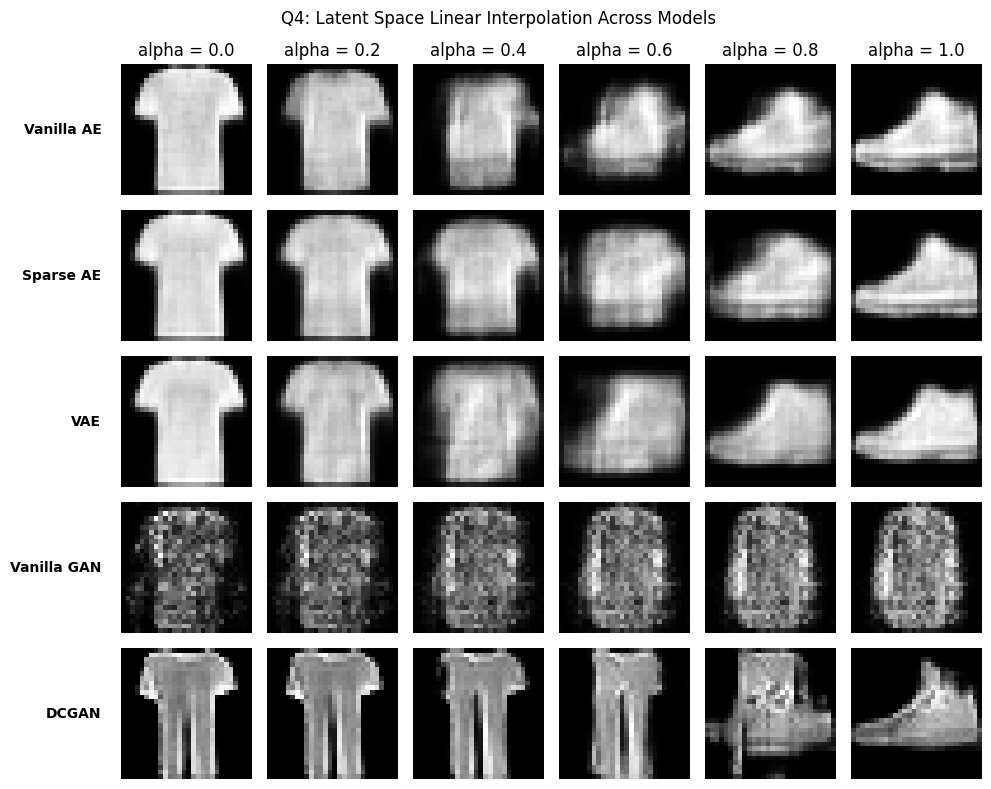

In [17]:
alphas_interp = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

img_A, img_B = None, None
for imgs, labels in test_loader:
    for i in range(len(labels)):
        if labels[i].item() == 0 and img_A is None:
            img_A = imgs[i:i+1].to(device)
        if labels[i].item() == 7 and img_B is None:
            img_B = imgs[i:i+1].to(device)
    if img_A is not None and img_B is not None:
        break

@torch.no_grad()
def interpolate_latents(zA, zB, decode_fn, rescale=False):
    imgs = []
    for a in alphas_interp:
        z = (1.0 - a) * zA + a * zB
        out = decode_fn(z)
        if rescale:
            out = ((out + 1.0) / 2.0).clamp(0.0, 1.0)
        imgs.append(out.cpu().squeeze())
    return imgs

with torch.no_grad():
    zA_van, zB_van = vanilla_ae.encode(img_A), vanilla_ae.encode(img_B)
    zA_spa, zB_spa = sparse_ae.encode(img_A), sparse_ae.encode(img_B)
    zA_vae, _ = vae.encode(img_A)
    zB_vae, _ = vae.encode(img_B)

    torch.manual_seed(SEED)
    zA_gan = torch.randn(1, GAN_LATENT_DIM, device=device)
    zB_gan = torch.randn(1, GAN_LATENT_DIM, device=device)

    interp_rows = {
        "Vanilla AE": interpolate_latents(zA_van, zB_van, vanilla_ae.decode),
        "Sparse AE":  interpolate_latents(zA_spa, zB_spa, sparse_ae.decode),
        "VAE":        interpolate_latents(zA_vae, zB_vae, vae.decode),
        "Vanilla GAN":interpolate_latents(zA_gan, zB_gan, vgan_G, rescale=True),
        "DCGAN":      interpolate_latents(zA_gan, zB_gan, dcgan_G, rescale=True),
    }

fig, axes = plt.subplots(5, len(alphas_interp), figsize=(10, 8))
for r, (model_name, img_list) in enumerate(interp_rows.items()):
    for c, img in enumerate(img_list):
        axes[r, c].imshow(img, cmap="gray")
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(f"alpha = {alphas_interp[c]}")
    axes[r, 0].text(-0.15, 0.5, model_name, transform=axes[r, 0].transAxes, fontsize=10, fontweight="bold", ha="right", va="center")

plt.suptitle("Q4: Latent Space Linear Interpolation Across Models", fontsize=12)
plt.tight_layout()
plt.show()

## 13. Q6 Helper Check (Anomaly Sensitivity) & Final Summary Table
- Quick check comparing Vanilla AE vs Sparse AE reconstruction error on normal test images vs corrupted/anomalous images.
- Clean final table combining all metrics from this notebook for your report.


In [18]:
@torch.no_grad()
def anomaly_mse_check(model):
    model.eval()
    normal_mses = []
    anomaly_mses = []
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        anomalous = (imgs + 0.5 * torch.randn_like(imgs)).clamp(0.0, 1.0)

        rec_norm, _ = model(imgs)
        rec_anom, _ = model(anomalous)

        normal_mses.append(F.mse_loss(rec_norm, imgs).item())
        anomaly_mses.append(F.mse_loss(rec_anom, anomalous).item())
    return np.mean(normal_mses), np.mean(anomaly_mses)

van_norm, van_anom = anomaly_mse_check(vanilla_ae)
spa_norm, spa_anom = anomaly_mse_check(sparse_ae)

print("=== Q6(1) Anomaly Detection Sensitivity Check ===")
print(f"Vanilla AE | Normal MSE: {van_norm:.5f} | Anomaly MSE: {van_anom:.5f} | Ratio: {van_anom/van_norm:.2f}x")
print(f"Sparse AE  | Normal MSE: {spa_norm:.5f} | Anomaly MSE: {spa_anom:.5f} | Ratio: {spa_anom/spa_norm:.2f}x")

summary_rows = []
for name in ["Vanilla AE", "Sparse AE", "VAE", "Vanilla GAN", "DCGAN", "DDPM"]:
    row = {
        "Model": name,
        "Test MSE": f"{recon_results[name]['Test MSE']:.5f}" if name in recon_results else "-",
        "Test PSNR (dB)": f"{recon_results[name]['Test PSNR (dB)']:.2f}" if name in recon_results else "-",
        "Test SSIM": f"{recon_results[name]['Test SSIM']:.4f}" if name in recon_results else "-",
        "FID (lower=better)": f"{fid_results[name]:.2f}" if name in fid_results else "-",
        "Latency 64 imgs (ms)": f"{latencies[name]:.2f}" if name in latencies else "-"
    }
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
print("\n=== Final Summary Table (All 6 Generative Models) ===")
display(summary_df)

=== Q6(1) Anomaly Detection Sensitivity Check ===
Vanilla AE | Normal MSE: 0.01242 | Anomaly MSE: 0.11289 | Ratio: 9.09x
Sparse AE  | Normal MSE: 0.01268 | Anomaly MSE: 0.11265 | Ratio: 8.89x

=== Final Summary Table (All 6 Generative Models) ===


,Model,Test MSE,Test PSNR (dB),Test SSIM,FID (lower=better),Latency 64 imgs (ms)
0,Vanilla AE,0.01242,19.95,0.7129,-,-
1,Sparse AE,0.01268,19.83,0.7140,-,-
2,VAE,0.01707,18.38,0.6642,106.14,0.41
3,Vanilla GAN,-,-,-,210.27,0.31
4,DCGAN,-,-,-,46.19,4.95
5,DDPM,-,-,-,132.94,585.84
